# Part B1 - Train the models (BiLSTM and BERT)
**Ali | 6:07 PM**

> **How to use this notebook:**
> 1. Runtime > Change runtime type > **T4 GPU** > Save.
> 2. Runtime > **Run all**.
>
> Training takes longer than our time slot, so it's fine if it doesn't finish. **Part B2** (`Ali_2_See_Results.ipynb`) shows the finished results.

---

## Step 1 - Get the workshop files

In [ ]:
!git clone https://github.com/sagarh12/forge-workshop.git

%cd /content/forge-workshop

!ls data/processed

Cloning into 'forge-workshop'...
remote: Enumerating objects: 65, done.
remote: Counting objects: 100% (65/65), done.
remote: Compressing objects: 100% (53/53), done.
remote: Total 65 (delta 17), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (65/65), 670.56 KiB | 11.18 MiB/s, done.
Resolving deltas: 100% (17/17), done.
/content/forge-workshop
meld_clean.csv	meld_context.csv  README.md


## Step 2 - Check the GPU

In [ ]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


GPU available: True
GPU: Tesla T4


## Step 3 - Load the dataset

In [ ]:
import pandas as pd

df = pd.read_csv("data/processed/meld_clean.csv")

print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())

print("\nDataset splits:")
print(df["split"].value_counts())

print("\nEmotion labels:")
print(df["label"].value_counts())

df.head()

Dataset shape: (13708, 6)

Columns: ['utterance', 'label', 'dialogue_id', 'utterance_id', 'speaker', 'split']

Dataset splits:
split
train    9989
test     2610
dev      1109
Name: count, dtype: int64

Emotion labels:
label
neutral     6436
joy         2308
surprise    1636
anger       1607
sadness     1002
disgust      361
fear         358
Name: count, dtype: int64


,utterance,label,dialogue_id,utterance_id,speaker,split
0,also I was the point person on my company's tr...,neutral,0,0,Chandler,train
1,You must've had your hands full.,neutral,0,1,The Interviewer,train
2,That I did. That I did.,neutral,0,2,Chandler,train
3,So let's talk a little bit about your duties.,neutral,0,3,The Interviewer,train
4,My duties? All right.,surprise,0,4,Chandler,train


## Step 4 - Setup and the official split

In [ ]:
import numpy as np
import random
import torch
import torch.nn as nn
import re

from collections import Counter
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Official MELD split
train_df = df[df["split"] == "train"].copy()
dev_df = df[df["split"] == "dev"].copy()
test_df = df[df["split"] == "test"].copy()

labels = [
    "anger", "disgust", "fear", "joy",
    "neutral", "sadness", "surprise"
]

label2id = {label: i for i, label in enumerate(labels)}
id2label = {i: label for label, i in label2id.items()}

assert len(train_df) == 9989
assert len(dev_df) == 1109
assert len(test_df) == 2610
assert set(df["label"]) == set(labels)

print("Training:", len(train_df))
print("Validation:", len(dev_df))
print("Testing:", len(test_df))
print("Label mapping:", label2id)
print("Device:", device)

Training: 9989
Validation: 1109
Testing: 2610
Label mapping: {'anger': 0, 'disgust': 1, 'fear': 2, 'joy': 3, 'neutral': 4, 'sadness': 5, 'surprise': 6}
Device: cuda


## Step 5 - Turn words into numbers

In [ ]:
MAX_LEN = 64
MAX_VOCAB = 15000

def tokenize(text):
    return re.findall(r"\w+|[^\w\s]", str(text).lower())

# Build vocabulary using training data only
counter = Counter()

for text in train_df["utterance"]:
    counter.update(tokenize(text))

vocab = {"<PAD>": 0, "<UNK>": 1}

for word, count in counter.most_common(MAX_VOCAB - 2):
    vocab[word] = len(vocab)

def encode(text):
    tokens = tokenize(text)[:MAX_LEN]

    ids = [vocab.get(token, 1) for token in tokens]

    length = max(len(ids), 1)

    ids += [0] * (MAX_LEN - len(ids))

    return ids, length

print("Vocabulary size:", len(vocab))
print("Example tokens:", tokenize("I am very happy!"))
print("Encoded example:", encode("I am very happy!"))

Vocabulary size: 5387
Example tokens: ['i', 'am', 'very', 'happy', '!']
Encoded example: ([5, 133, 166, 249, 6, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 5)


## Step 6 - Feed the data to the model

In [ ]:
class EmotionDataset(Dataset):

    def __init__(self, dataframe):
        self.texts = dataframe["utterance"].tolist()
        self.labels = dataframe["label"].tolist()

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        ids, length = encode(self.texts[idx])

        return (
            torch.tensor(ids, dtype=torch.long),
            torch.tensor(length, dtype=torch.long),
            torch.tensor(
                label2id[self.labels[idx]],
                dtype=torch.long
            )
        )

BATCH_SIZE = 64

train_loader = DataLoader(
    EmotionDataset(train_df),
    batch_size=BATCH_SIZE,
    shuffle=True
)

dev_loader = DataLoader(
    EmotionDataset(dev_df),
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    EmotionDataset(test_df),
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Data loaders ready.")

Data loaders ready.


## Step 7 - The BiLSTM model

In [ ]:
class BiLSTMClassifier(nn.Module):

    def __init__(self, vocab_size, num_classes):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            128,
            padding_idx=0
        )

        self.lstm = nn.LSTM(
            input_size=128,
            hidden_size=128,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(0.3)

        self.fc = nn.Linear(256, num_classes)

    def forward(self, x, lengths):

        embedded = self.embedding(x)

        packed = nn.utils.rnn.pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, (hidden, _) = self.lstm(packed)

        combined = torch.cat(
            (hidden[-2], hidden[-1]),
            dim=1
        )

        combined = self.dropout(combined)

        return self.fc(combined)


model = BiLSTMClassifier(
    vocab_size=len(vocab),
    num_classes=len(labels)
).to(device)

print(model)

print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters()
        if p.requires_grad)
)

BiLSTMClassifier(
  (embedding): Embedding(5387, 128, padding_idx=0)
  (lstm): LSTM(128, 128, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=7, bias=True)
)
Trainable parameters: 955527


## Step 8 - Train the BiLSTM

In [ ]:
import time

EPOCHS = 10
LEARNING_RATE = 0.001

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
    "val_f1": []
}

def run_epoch(loader, training=False):

    model.train(training)

    total_loss = 0
    predictions = []
    actual = []

    with torch.set_grad_enabled(training):

        for x, lengths, y in loader:

            x = x.to(device)
            y = y.to(device)

            if training:
                optimizer.zero_grad()

            logits = model(x, lengths)
            loss = criterion(logits, y)

            if training:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * y.size(0)

            predictions.extend(
                logits.argmax(dim=1).cpu().tolist()
            )

            actual.extend(y.cpu().tolist())

    return (
        total_loss / len(loader.dataset),
        accuracy_score(actual, predictions),
        f1_score(
            actual,
            predictions,
            labels=list(range(len(labels))),
            average="macro",
            zero_division=0
        )
    )

start_time = time.time()
best_f1 = -1
best_epoch = 0

for epoch in range(EPOCHS):

    train_loss, train_acc, _ = run_epoch(
        train_loader, training=True
    )

    val_loss, val_acc, val_f1 = run_epoch(
        dev_loader
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    history["val_f1"].append(val_f1)

    if val_f1 > best_f1:
        best_f1 = val_f1
        best_epoch = epoch + 1

        torch.save(
            model.state_dict(),
            "/content/bilstm_best.pt"
        )

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Train acc: {train_acc:.4f} | "
        f"Val acc: {val_acc:.4f} | "
        f"Val F1: {val_f1:.4f}"
    )

training_time = time.time() - start_time

model.load_state_dict(
    torch.load(
        "/content/bilstm_best.pt",
        map_location=device
    )
)

print(f"\nTraining time: {training_time / 60:.2f} minutes")
print("Best epoch:", best_epoch)
print("Best validation F1:", best_f1)

Epoch 1/10 | Train loss: 1.3649 | Val loss: 1.3621 | Train acc: 0.5529 | Val acc: 0.5347 | Val F1: 0.2639
Epoch 2/10 | Train loss: 1.2104 | Val loss: 1.3475 | Train acc: 0.5988 | Val acc: 0.5500 | Val F1: 0.2822
Epoch 3/10 | Train loss: 1.1136 | Val loss: 1.3258 | Train acc: 0.6281 | Val acc: 0.5564 | Val F1: 0.3163
Epoch 4/10 | Train loss: 1.0086 | Val loss: 1.3769 | Train acc: 0.6629 | Val acc: 0.5555 | Val F1: 0.3431
Epoch 5/10 | Train loss: 0.8935 | Val loss: 1.4383 | Train acc: 0.7024 | Val acc: 0.5437 | Val F1: 0.3229
Epoch 6/10 | Train loss: 0.7527 | Val loss: 1.5262 | Train acc: 0.7503 | Val acc: 0.5455 | Val F1: 0.3384
Epoch 7/10 | Train loss: 0.6170 | Val loss: 1.6537 | Train acc: 0.7965 | Val acc: 0.5167 | Val F1: 0.3277
Epoch 8/10 | Train loss: 0.4838 | Val loss: 1.8362 | Train acc: 0.8455 | Val acc: 0.5131 | Val F1: 0.3114
Epoch 9/10 | Train loss: 0.3788 | Val loss: 2.0268 | Train acc: 0.8811 | Val acc: 0.4986 | Val F1: 0.3299
Epoch 10/10 | Train loss: 0.2984 | Val loss: 2

## Step 9 - Test the BiLSTM

In [ ]:
from sklearn.metrics import classification_report

model.eval()

test_predictions = []
test_actual = []

with torch.no_grad():

    for x, lengths, y in test_loader:

        x = x.to(device)

        logits = model(x, lengths)

        predictions = logits.argmax(dim=1)

        test_predictions.extend(
            predictions.cpu().tolist()
        )

        test_actual.extend(y.tolist())

test_accuracy = accuracy_score(
    test_actual,
    test_predictions
)

test_f1 = f1_score(
    test_actual,
    test_predictions,
    labels=list(range(len(labels))),
    average="macro",
    zero_division=0
)

print("Total predictions:", len(test_predictions))
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test macro F1: {test_f1:.4f}")

print("\nClassification report:\n")

print(classification_report(
    test_actual,
    test_predictions,
    labels=list(range(len(labels))),
    target_names=labels,
    zero_division=0
))

Total predictions: 2610
Test accuracy: 0.6042
Test macro F1: 0.3368

Classification report:

              precision    recall  f1-score   support

       anger       0.43      0.31      0.36       345
     disgust       0.00      0.00      0.00        68
        fear       0.27      0.06      0.10        50
         joy       0.51      0.48      0.50       402
     neutral       0.66      0.90      0.76      1256
     sadness       0.40      0.09      0.14       208
    surprise       0.56      0.44      0.49       281

    accuracy                           0.60      2610
   macro avg       0.41      0.33      0.34      2610
weighted avg       0.55      0.60      0.56      2610



## Step 10 - Save the BiLSTM results and training curve

In [ ]:
results = pd.DataFrame({
    "utterance": test_df["utterance"].tolist(),
    "true_label": test_df["label"].tolist(),
    "predicted_label": [
        id2label[i] for i in test_predictions
    ],
    "model_name": "bilstm"
})

assert len(results) == 2610

assert [
    id2label[i] for i in test_actual
] == results["true_label"].tolist()

correct = results[
    results["true_label"] == results["predicted_label"]
]

incorrect = results[
    results["true_label"] != results["predicted_label"]
]

print("Correct predictions:", len(correct))
print("Incorrect predictions:", len(incorrect))

print("\nCorrect examples:")
display(correct.sample(10, random_state=42))

print("\nIncorrect examples:")
display(incorrect.sample(10, random_state=42))

Correct predictions: 1577
Incorrect predictions: 1033

Correct examples:


,utterance,true_label,predicted_label,model_name
2089,"Thank you for your patience, you're the next c...",neutral,neutral,bilstm
1349,WhatWhy wouldn't you want me at your wedding?,anger,anger,bilstm
1971,"Yeah, I guess so.",neutral,neutral,bilstm
881,Sure.,neutral,neutral,bilstm
849,"Oh, um, Chandler?",neutral,neutral,bilstm
2538,Come in.,neutral,neutral,bilstm
860,"I gotta go Monica, my uh, my sushi's here!",neutral,neutral,bilstm
457,Hi!,joy,joy,bilstm
815,"Yeah, but they didn't ask me!",anger,anger,bilstm
107,I don't know.,neutral,neutral,bilstm



Incorrect examples:


,utterance,true_label,predicted_label,model_name
745,What's wrong with you?,anger,surprise,bilstm
1118,"Then he comes over! ""I'm so worried about you....",disgust,anger,bilstm
1597,Now I can't believe it! What? Rachel's pregnan...,surprise,anger,bilstm
343,For Chandler!,anger,neutral,bilstm
1361,"Man to uh, me.",neutral,sadness,bilstm
928,"Ow! My ass. Okay. Okay. Oh, shhh!",anger,surprise,bilstm
1504,Ahhhh!!,surprise,anger,bilstm
1457,"And the way she looked at me, pure lust.",joy,neutral,bilstm
577,It's Clint!,anger,joy,bilstm
527,"I mean, I remember a time when",sadness,neutral,bilstm


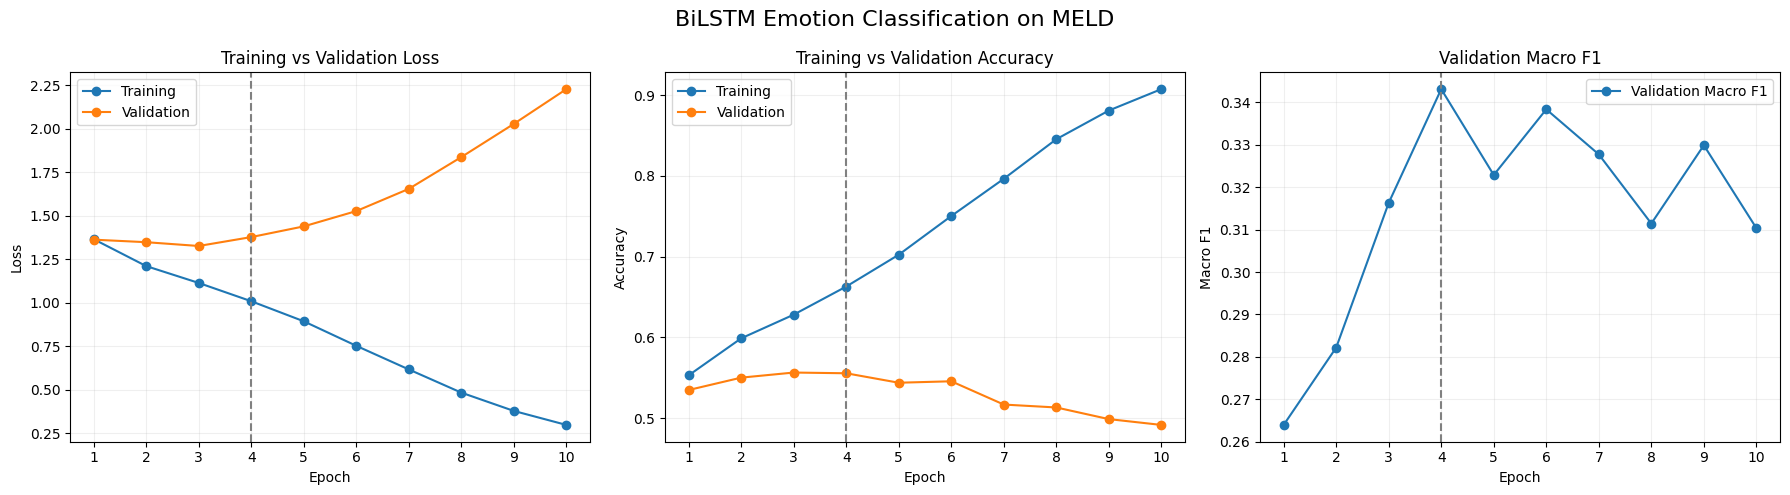

In [ ]:
import matplotlib.pyplot as plt
import os

os.makedirs("outputs/figures", exist_ok=True)

epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Loss
axes[0].plot(
    epochs, history["train_loss"],
    marker="o", label="Training"
)

axes[0].plot(
    epochs, history["val_loss"],
    marker="o", label="Validation"
)

axes[0].set_title("Training vs Validation Loss")
axes[0].set_ylabel("Loss")
axes[0].legend()

# Accuracy
axes[1].plot(
    epochs, history["train_acc"],
    marker="o", label="Training"
)

axes[1].plot(
    epochs, history["val_acc"],
    marker="o", label="Validation"
)

axes[1].set_title("Training vs Validation Accuracy")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

# Macro F1
axes[2].plot(
    epochs, history["val_f1"],
    marker="o", label="Validation Macro F1"
)

axes[2].set_title("Validation Macro F1")
axes[2].set_ylabel("Macro F1")
axes[2].legend()

for ax in axes:

    ax.axvline(
        best_epoch,
        color="gray",
        linestyle="--"
    )

    ax.set_xlabel("Epoch")
    ax.set_xticks(list(epochs))
    ax.grid(alpha=0.2)

fig.suptitle(
    "BiLSTM Emotion Classification on MELD",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "outputs/figures/bilstm_training_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
history_df = pd.DataFrame(history)

history_df.insert(
    0, "epoch", range(1, len(history_df) + 1)
)

history_df.to_csv(
    "outputs/figures/bilstm_training_history.csv",
    index=False
)

display(history_df)

,epoch,train_loss,val_loss,train_acc,val_acc,val_f1
0,1,1.364944,1.362085,0.552908,0.534716,0.263945
1,2,1.210394,1.347535,0.598759,0.550045,0.282178
2,3,1.113629,1.325800,0.628091,0.556357,0.316301
3,4,1.008644,1.376883,0.662929,0.555455,0.343126
4,5,0.893471,1.438268,0.702373,0.543733,0.322876
5,6,0.752690,1.526200,0.750325,0.545537,0.338361
6,7,0.617046,1.653679,0.796476,0.516682,0.327736
7,8,0.483803,1.836204,0.845530,0.513075,0.311433
8,9,0.378804,2.026850,0.881069,0.498647,0.329894
9,10,0.298409,2.226350,0.907598,0.491434,0.310351


## Step 11 - Save predictions in the shared format
Uses `save_predictions()` from Step 7 of the base notebook, so Sheheryar's scoreboard can read the file.

In [ ]:
import json

with open("forge_workshop_base.ipynb", "r") as f:
    notebook = json.load(f)

for cell in notebook["cells"]:

    if cell["cell_type"] == "code":

        source = "".join(cell["source"])

        if "def save_predictions" in source:
            print(source)

ALLOWED_MODELS = {"bilstm", "bert_finetuned", "zero_shot", "few_shot", "balanced_few_shot"}

def save_predictions(X, y_true, y_pred, model_name: str, full_test_set: bool = True):
    """
    Save model predictions in the standard format.

    Args:
        X            : utterances, in the same order as the official test set
        y_true       : true labels
        y_pred       : predicted labels
        model_name   : one of ALLOWED_MODELS
        full_test_set: set False only for capped runs such as 100-row LLM demos
    """
    assert model_name in ALLOWED_MODELS, f"model_name must be one of {sorted(ALLOWED_MODELS)}"
    assert len(X) == len(y_true) == len(y_pred), "X, y_true and y_pred must be the same length"

    # Rows must be the official test rows, in the official order
    n = len(X)
    assert list(X) == X_test[:n], "Utterances do not match the official test set order. Did you re-split or shuffle?"
    assert list(y_true) == y_test[:n], "true_label does not match the offic

In [ ]:
import os
import json

os.makedirs("outputs/predictions", exist_ok=True)

X_test = test_df["utterance"].tolist()
y_test = test_df["label"].tolist()

EXPECTED_LABELS = set(labels)

with open("forge_workshop_base.ipynb", "r") as f:
    notebook = json.load(f)

for cell in notebook["cells"]:
    if cell["cell_type"] == "code":
        source = "".join(cell["source"])

        if "def save_predictions" in source:
            exec(source)
            break

bilstm_results = save_predictions(
    X_test,
    y_test,
    [id2label[i] for i in test_predictions],
    model_name="bilstm",
    full_test_set=True
)

Predictions saved to outputs/predictions/bilstm_predictions.csv (2610 rows)


## Step 12 - Check and download the BiLSTM results

In [ ]:
bilstm_saved = pd.read_csv(
    "outputs/predictions/bilstm_predictions.csv"
)

assert len(bilstm_saved) == 2610

assert list(bilstm_saved.columns) == [
    "utterance",
    "true_label",
    "predicted_label",
    "model_name"
]

assert bilstm_saved["utterance"].tolist() == X_test
assert bilstm_saved["true_label"].tolist() == y_test
assert set(bilstm_saved["model_name"]) == {"bilstm"}

print("BiLSTM CSV passed all checks.")

display(bilstm_saved.head())

bilstm_summary = {
    "model": "bilstm",
    "test_accuracy": test_accuracy,
    "test_macro_f1": test_f1,
    "training_seconds": training_time,
    "best_epoch": best_epoch,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "parameters": sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )
}

with open("outputs/figures/bilstm_summary.json", "w") as f:
    json.dump(bilstm_summary, f, indent=2)

BiLSTM CSV passed all checks.


,utterance,true_label,predicted_label,model_name
0,Why do all you're coffee mugs have numbers on ...,surprise,neutral,bilstm
1,Oh. That's so Monica can keep track. That way ...,anger,neutral,bilstm
2,Y'know what?,neutral,neutral,bilstm
3,"Come on, Lydia, you can do it.",neutral,neutral,bilstm
4,Push!,joy,joy,bilstm


In [ ]:
from google.colab import files

!zip -j /content/bilstm_results.zip \
    outputs/predictions/bilstm_predictions.csv \
    outputs/figures/bilstm_training_curve.png \
    outputs/figures/bilstm_training_history.csv \
    outputs/figures/bilstm_summary.json

files.download("/content/bilstm_results.zip")

  adding: bilstm_predictions.csv (deflated 70%)
  adding: bilstm_training_curve.png (deflated 14%)
  adding: bilstm_training_history.csv (deflated 48%)
  adding: bilstm_summary.json (deflated 32%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 13 - Set up BERT

In [ ]:
!pip -q install transformers

In [ ]:
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

MODEL_NAME = "bert-base-uncased"

bert_tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

bert_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=7,
    id2label=id2label,
    label2id=label2id
).to(device)

print("BERT model loaded.")

print(
    "Trainable parameters:",
    sum(p.numel() for p in bert_model.parameters()
        if p.requires_grad)
)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT model loaded.
Trainable parameters: 109487623


In [ ]:
class BERTEmotionDataset(Dataset):

    def __init__(self, dataframe):

        self.encodings = bert_tokenizer(
            dataframe["utterance"].astype(str).tolist(),
            truncation=True,
            padding="max_length",
            max_length=64,
            return_tensors="pt"
        )

        self.targets = [
            label2id[label]
            for label in dataframe["label"]
        ]

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, idx):

        item = {
            key: value[idx]
            for key, value in self.encodings.items()
        }

        item["labels"] = torch.tensor(
            self.targets[idx],
            dtype=torch.long
        )

        return item


BERT_BATCH_SIZE = 32

bert_train_loader = DataLoader(
    BERTEmotionDataset(train_df),
    batch_size=BERT_BATCH_SIZE,
    shuffle=True
)

bert_dev_loader = DataLoader(
    BERTEmotionDataset(dev_df),
    batch_size=BERT_BATCH_SIZE,
    shuffle=False
)

bert_test_loader = DataLoader(
    BERTEmotionDataset(test_df),
    batch_size=BERT_BATCH_SIZE,
    shuffle=False
)

print("BERT data loaders ready.")

BERT data loaders ready.


## Step 14 - BERT training helpers

In [ ]:
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup
from tqdm.auto import tqdm

BERT_EPOCHS = 4
BERT_LR = 2e-5

bert_optimizer = AdamW(
    bert_model.parameters(),
    lr=BERT_LR,
    weight_decay=0.01
)

total_steps = (
    len(bert_train_loader) * BERT_EPOCHS
)

scheduler = get_linear_schedule_with_warmup(
    bert_optimizer,
    num_warmup_steps=int(total_steps * 0.1),
    num_training_steps=total_steps
)

bert_history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
    "val_f1": []
}

In [ ]:
def run_bert_epoch(loader, training=False):

    bert_model.train(training)

    total_loss = 0
    predictions = []
    actual = []

    with torch.set_grad_enabled(training):

        for batch in tqdm(
            loader,
            leave=False,
            desc="Training" if training else "Evaluating"
        ):

            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            if training:
                bert_optimizer.zero_grad()

            outputs = bert_model(**batch)

            loss = outputs.loss
            logits = outputs.logits

            if training:

                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    bert_model.parameters(), 1.0
                )

                bert_optimizer.step()
                scheduler.step()

            total_loss += (
                loss.item() * batch["labels"].size(0)
            )

            predictions.extend(
                logits.argmax(dim=1).cpu().tolist()
            )

            actual.extend(
                batch["labels"].cpu().tolist()
            )

    return (
        total_loss / len(loader.dataset),
        accuracy_score(actual, predictions),
        f1_score(
            actual,
            predictions,
            labels=list(range(len(labels))),
            average="macro",
            zero_division=0
        )
    )

## Step 15 - Fine-tune BERT

In [ ]:
import time

bert_start_time = time.time()

bert_best_f1 = -1
bert_best_epoch = 0

for epoch in range(BERT_EPOCHS):

    train_loss, train_acc, _ = run_bert_epoch(
        bert_train_loader,
        training=True
    )

    val_loss, val_acc, val_f1 = run_bert_epoch(
        bert_dev_loader
    )

    bert_history["train_loss"].append(train_loss)
    bert_history["val_loss"].append(val_loss)
    bert_history["train_acc"].append(train_acc)
    bert_history["val_acc"].append(val_acc)
    bert_history["val_f1"].append(val_f1)

    if val_f1 > bert_best_f1:

        bert_best_f1 = val_f1
        bert_best_epoch = epoch + 1

        torch.save(
            bert_model.state_dict(),
            "/content/bert_best.pt"
        )

    print(
        f"Epoch {epoch+1}/{BERT_EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Train acc: {train_acc:.4f} | "
        f"Val acc: {val_acc:.4f} | "
        f"Val F1: {val_f1:.4f}"
    )

bert_training_time = time.time() - bert_start_time

bert_model.load_state_dict(
    torch.load(
        "/content/bert_best.pt",
        map_location="cpu"
    )
)

print(
    f"Training time: "
    f"{bert_training_time / 60:.2f} minutes"
)

print("Best epoch:", bert_best_epoch)
print("Best validation F1:", bert_best_f1)

Training:   0%|          | 0/313 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/35 [00:00<?, ?it/s]

Epoch 1/4 | Train loss: 1.3027 | Val loss: 1.1668 | Train acc: 0.5626 | Val acc: 0.6141 | Val F1: 0.3805


Training:   0%|          | 0/313 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/35 [00:00<?, ?it/s]

Epoch 2/4 | Train loss: 0.9938 | Val loss: 1.1449 | Train acc: 0.6762 | Val acc: 0.6041 | Val F1: 0.3826


... (2 outputs left out)

Epoch 3/4 | Train loss: 0.8261 | Val loss: 1.1785 | Train acc: 0.7396 | Val acc: 0.6123 | Val F1: 0.3925


Training:   0%|          | 0/313 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/35 [00:00<?, ?it/s]

Epoch 4/4 | Train loss: 0.6975 | Val loss: 1.1862 | Train acc: 0.7822 | Val acc: 0.6132 | Val F1: 0.4097
Training time: 7.80 minutes
Best epoch: 4
Best validation F1: 0.4096795823670538


## Step 16 - Check the saved files

In [ ]:
import os
import torch

print("GPU available:", torch.cuda.is_available())

print("\nSaved files:")
print("BERT checkpoint:", os.path.exists("/content/bert_best.pt"))
print("BiLSTM checkpoint:", os.path.exists("/content/bilstm_best.pt"))
print("Repository:", os.path.exists("/content/forge-workshop"))

print("\nAvailable variables:")

for name in [
    "df",
    "bert_model",
    "bert_tokenizer",
    "bert_test_loader",
    "bert_history",
    "bert_training_time",
    "bert_best_epoch",
    "save_predictions",
    "bilstm_summary"
]:
    print(name, ":", name in globals())

NameError: name 'bert_model' is not defined

In [6]:
import os
import torch

print("GPU available:", torch.cuda.is_available())

print("\nSaved files:")
print("BERT checkpoint:", os.path.exists("/content/bert_best.pt"))
print("BiLSTM checkpoint:", os.path.exists("/content/bilstm_best.pt"))
print("Repository:", os.path.exists("/content/forge-workshop"))

print("\nAvailable variables:")

for name in [
    "df",
    "bert_model",
    "bert_tokenizer",
    "bert_test_loader",
    "bert_history",
    "bert_training_time",
    "bert_best_epoch",
    "save_predictions",
    "bilstm_summary"
]:
    print(name, ":", name in globals())

GPU available: True

Saved files:
BERT checkpoint: False
BiLSTM checkpoint: False
Repository: False

Available variables:
df : False
bert_model : False
bert_tokenizer : False
bert_test_loader : False
bert_history : False
bert_training_time : False
bert_best_epoch : False
save_predictions : False
bilstm_summary : False


## Extra - Back up to Google Drive (for Ali)
These cells copy the results to Google Drive. **You don't need them during the workshop.**

> If you used Run all, Colab asks to connect Google Drive at this point. You can click **Cancel** and stop here: Part B2 shows the finished results.

In [9]:
from google.colab import drive

drive.mount("/content/drive")

!git clone https://github.com/sagarh12/forge-workshop.git

%cd /content/forge-workshop

Mounted at /content/drive
Cloning into 'forge-workshop'...
remote: Enumerating objects: 65, done.
remote: Counting objects: 100% (65/65), done.
remote: Compressing objects: 100% (53/53), done.
remote: Total 65 (delta 17), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (65/65), 670.56 KiB | 2.21 MiB/s, done.
Resolving deltas: 100% (17/17), done.
/content/forge-workshop


In [10]:
import os

BACKUP_DIR = "/content/drive/MyDrive/Forge_Workshop"

os.makedirs(BACKUP_DIR, exist_ok=True)

print("Permanent backup folder ready.")

Permanent backup folder ready.


import pandas as pd
import numpy as np
import random
import torch
import torch.nn as nn
import json
import time
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

df = pd.read_csv("data/processed/meld_clean.csv")

train_df = df[df["split"] == "train"].copy()
dev_df = df[df["split"] == "dev"].copy()
test_df = df[df["split"] == "test"].copy()

labels = [
    "anger", "disgust", "fear", "joy",
    "neutral", "sadness", "surprise"
]

label2id = {label: i for i, label in enumerate(labels)}
id2label = {i: label for label, i in label2id.items()}

X_test = test_df["utterance"].tolist()
y_test = test_df["label"].tolist()

EXPECTED_LABELS = set(labels)

assert len(train_df) == 9989
assert len(dev_df) == 1109
assert len(test_df) == 2610

# Restore the shared saving function
with open("forge_workshop_base.ipynb") as f:
    notebook = json.load(f)

for cell in notebook["cells"]:
    if cell["cell_type"] == "code":
        source = "".join(cell["source"])

        if "def save_predictions" in source:
            exec(source)
            break

# Restore BiLSTM results
with open("outputs/figures/bilstm_summary.json") as f:
    bilstm_summary = json.load(f)

bilstm_saved = pd.read_csv(
    "outputs/predictions/bilstm_predictions.csv"
)

assert bilstm_saved["utterance"].tolist() == X_test
assert bilstm_saved["true_label"].tolist() == y_test

print("Dataset restored.")
print("BiLSTM alignment verified.")
print("Saving function restored.")
print("Device:", device)

In [14]:
required = [
    "bert_model",
    "bert_train_loader",
    "bert_dev_loader",
    "bert_optimizer",
    "bert_history",
    "BERT_EPOCHS",
    "scheduler",
    "run_bert_epoch",
    "BACKUP_DIR",
    "json",
    "torch"
]

missing = [name for name in required if name not in globals()]

if missing:
    print("Missing variables:", missing)
else:
    print("All required variables are ready!")

Missing variables: ['bert_model', 'bert_train_loader', 'bert_dev_loader', 'bert_optimizer', 'bert_history', 'BERT_EPOCHS', 'scheduler', 'run_bert_epoch', 'json']


In [15]:
import os

print("Repository:", os.path.exists(
    "/content/forge-workshop"
))

print("Dataset:", os.path.exists(
    "/content/forge-workshop/data/processed/meld_clean.csv"
))

print("BiLSTM predictions:", os.path.exists(
    "/content/forge-workshop/outputs/predictions/bilstm_predictions.csv"
))

print("Google Drive:", os.path.exists(
    "/content/drive/MyDrive"
))

print("Current directory:", os.getcwd())

Repository: True
Dataset: True
BiLSTM predictions: False
Google Drive: True
Current directory: /content/forge-workshop


In [16]:
from google.colab import files
import os
import zipfile
import shutil

os.chdir("/content/forge-workshop")

BACKUP_DIR = "/content/drive/MyDrive/Forge_Workshop"
os.makedirs(BACKUP_DIR, exist_ok=True)

uploaded = files.upload()

os.makedirs("outputs/predictions", exist_ok=True)
os.makedirs("outputs/figures", exist_ok=True)

with zipfile.ZipFile("bilstm_results.zip", "r") as z:
    z.extractall("/content/bilstm_backup")

for filename in os.listdir("/content/bilstm_backup"):

    if filename == "bilstm_predictions.csv":
        destination = "outputs/predictions"
    else:
        destination = "outputs/figures"

    shutil.copy(
        f"/content/bilstm_backup/{filename}",
        destination
    )

shutil.copy("bilstm_results.zip", BACKUP_DIR)

print("BiLSTM results restored and backed up.")

Saving bilstm_results.zip to bilstm_results.zip
BiLSTM results restored and backed up.


In [17]:
for path in [
    "outputs/predictions/bilstm_predictions.csv",
    "outputs/figures/bilstm_training_curve.png",
    "outputs/figures/bilstm_training_history.csv",
    "outputs/figures/bilstm_summary.json"
]:
    print(os.path.exists(path), path)

True outputs/predictions/bilstm_predictions.csv
True outputs/figures/bilstm_training_curve.png
True outputs/figures/bilstm_training_history.csv
True outputs/figures/bilstm_summary.json


In [19]:
import time
import json

required = [
    "bert_model",
    "bert_tokenizer",
    "bert_train_loader",
    "bert_dev_loader",
    "bert_test_loader",
    "bert_optimizer",
    "bert_history",
    "BERT_EPOCHS",
    "scheduler",
    "run_bert_epoch",
    "BACKUP_DIR",
    "json",
    "torch",
    "time",
    "save_predictions",
    "bilstm_summary"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    print("Missing variables:", missing)
else:
    print("All required variables are ready!")
    print("GPU:", torch.cuda.get_device_name(0))
    print("Backup location:", BACKUP_DIR)

Missing variables: ['bert_model', 'bert_tokenizer', 'bert_train_loader', 'bert_dev_loader', 'bert_test_loader', 'bert_optimizer', 'bert_history', 'BERT_EPOCHS', 'scheduler', 'run_bert_epoch', 'save_predictions', 'bilstm_summary']


In [20]:
import os
import zipfile
import shutil
from google.colab import files

os.chdir("/content/forge-workshop")

BACKUP_DIR = "/content/drive/MyDrive/Forge_Workshop"

os.makedirs(BACKUP_DIR, exist_ok=True)
os.makedirs("outputs/predictions", exist_ok=True)
os.makedirs("outputs/figures", exist_ok=True)

zip_path = f"{BACKUP_DIR}/bilstm_results.zip"

if not os.path.exists(zip_path):
    uploaded = files.upload()

    with open(zip_path, "wb") as f:
        f.write(uploaded["bilstm_results.zip"])

with zipfile.ZipFile(zip_path, "r") as z:
    for name in z.namelist():

        filename = os.path.basename(name)

        if not filename:
            continue

        if filename == "bilstm_predictions.csv":
            destination = f"outputs/predictions/{filename}"
        else:
            destination = f"outputs/figures/{filename}"

        with open(destination, "wb") as f:
            f.write(z.read(name))

required_files = [
    "outputs/predictions/bilstm_predictions.csv",
    "outputs/figures/bilstm_training_curve.png",
    "outputs/figures/bilstm_training_history.csv",
    "outputs/figures/bilstm_summary.json"
]

for path in required_files:
    assert os.path.exists(path), f"Missing: {path}"
    print("Restored:", path)

print("\nBiLSTM successfully restored.")

Restored: outputs/predictions/bilstm_predictions.csv
Restored: outputs/figures/bilstm_training_curve.png
Restored: outputs/figures/bilstm_training_history.csv
Restored: outputs/figures/bilstm_summary.json

BiLSTM successfully restored.


## Step 17 - Test BERT and save its predictions

Testing BERT:   0%|          | 0/82 [00:00<?, ?it/s]

Total predictions: 2610
Test accuracy: 0.6387
Test macro F1: 0.4350

Classification report:

              precision    recall  f1-score   support

       anger       0.48      0.46      0.47       345
     disgust       0.36      0.06      0.10        68
        fear       0.33      0.12      0.18        50
         joy       0.58      0.64      0.61       402
     neutral       0.76      0.80      0.78      1256
     sadness       0.37      0.31      0.34       208
    surprise       0.54      0.61      0.57       281

    accuracy                           0.64      2610
   macro avg       0.49      0.43      0.44      2610
weighted avg       0.62      0.64      0.63      2610

Predictions saved to outputs/predictions/bert_finetuned_predictions.csv (2610 rows)

Correct predictions: 1667
Incorrect predictions: 943

Correct examples:


,utterance,true_label,predicted_label,model_name
1481,Is that too much to ask after six years?!,anger,anger,bert_finetuned
1562,Would,neutral,neutral,bert_finetuned
629,"Hey! Guys, this is Tabatha . I'll see you tomo...",neutral,neutral,bert_finetuned
1148,"Can you, can you hang on a second?",neutral,neutral,bert_finetuned
2536,"No, she's at a faculty meeting.",neutral,neutral,bert_finetuned
214,"No, it was a fight.",neutral,neutral,bert_finetuned
1531,"Oh, I think I saw some in here.",neutral,neutral,bert_finetuned
115,"Well, I'm not I'm not at all surprised they fe...",neutral,neutral,bert_finetuned
531,I bet he can.,neutral,neutral,bert_finetuned
447,All weekend? That's a whole lotta naked.,surprise,surprise,bert_finetuned



Incorrect examples:


,utterance,true_label,predicted_label,model_name
271,There's something new in the bowl.,surprise,neutral,bert_finetuned
742,What is the worse part?,neutral,sadness,bert_finetuned
2231,Can I get some ice here?!,sadness,anger,bert_finetuned
59,"Oh, Bob, he was nothing compared to you. I had...",sadness,joy,bert_finetuned
78,Isn't that mine?,neutral,joy,bert_finetuned
773,"Noo way, Kevin.",joy,neutral,bert_finetuned
1540,"Look, it’s not that easy. She said she wanted ...",sadness,neutral,bert_finetuned
724,Rachel always cries!,anger,joy,bert_finetuned
915,"Yeah, I said what was okay when I thought she ...",anger,neutral,bert_finetuned
899,Why are there only two of you?,fear,surprise,bert_finetuned


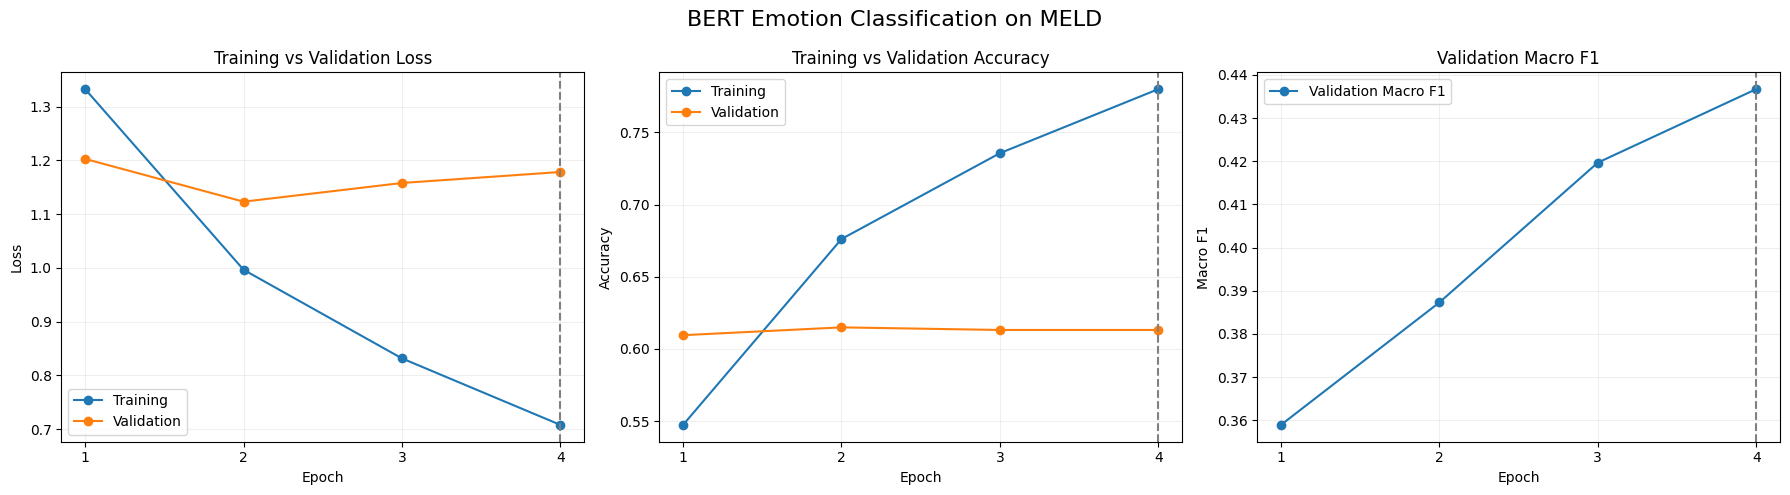


BERT evaluation completed and backed up.


In [26]:
# Evaluate the model

bert_model.eval()

bert_predictions = []
bert_actual = []

with torch.no_grad():

    for batch in tqdm(
        bert_test_loader,
        desc="Testing BERT"
    ):

        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        outputs = bert_model(**batch)

        predictions = outputs.logits.argmax(dim=1)

        bert_predictions.extend(
            predictions.cpu().tolist()
        )

        bert_actual.extend(
            batch["labels"].cpu().tolist()
        )

bert_test_accuracy = accuracy_score(
    bert_actual,
    bert_predictions
)

bert_test_f1 = f1_score(
    bert_actual,
    bert_predictions,
    labels=list(range(len(labels))),
    average="macro",
    zero_division=0
)

print("Total predictions:", len(bert_predictions))
print(f"Test accuracy: {bert_test_accuracy:.4f}")
print(f"Test macro F1: {bert_test_f1:.4f}")

print("\nClassification report:\n")

print(classification_report(
    bert_actual,
    bert_predictions,
    labels=list(range(len(labels))),
    target_names=labels,
    zero_division=0
))

# Save prediction CSV

assert len(bert_predictions) == 2610

assert [
    id2label[i] for i in bert_actual
] == y_test

bert_results = save_predictions(
    X_test,
    y_test,
    [id2label[i] for i in bert_predictions],
    model_name="bert_finetuned",
    full_test_set=True
)

# Back up predictions immediately

os.makedirs(
    f"{BACKUP_DIR}/outputs/predictions",
    exist_ok=True
)

shutil.copy(
    "outputs/predictions/bert_finetuned_predictions.csv",
    f"{BACKUP_DIR}/outputs/predictions/"
)

# Correct and incorrect predictions

bert_correct = bert_results[
    bert_results["true_label"] ==
    bert_results["predicted_label"]
]

bert_incorrect = bert_results[
    bert_results["true_label"] !=
    bert_results["predicted_label"]
]

print("\nCorrect predictions:", len(bert_correct))
print("Incorrect predictions:", len(bert_incorrect))

print("\nCorrect examples:")
display(bert_correct.sample(
    min(10, len(bert_correct)),
    random_state=42
))

print("\nIncorrect examples:")
display(bert_incorrect.sample(
    min(10, len(bert_incorrect)),
    random_state=42
))

# Generate training curves

epochs = range(
    1, len(bert_history["train_loss"]) + 1
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(
    epochs, bert_history["train_loss"],
    marker="o", label="Training"
)

axes[0].plot(
    epochs, bert_history["val_loss"],
    marker="o", label="Validation"
)

axes[0].set_title("Training vs Validation Loss")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(
    epochs, bert_history["train_acc"],
    marker="o", label="Training"
)

axes[1].plot(
    epochs, bert_history["val_acc"],
    marker="o", label="Validation"
)

axes[1].set_title("Training vs Validation Accuracy")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

axes[2].plot(
    epochs, bert_history["val_f1"],
    marker="o", label="Validation Macro F1"
)

axes[2].set_title("Validation Macro F1")
axes[2].set_ylabel("Macro F1")
axes[2].legend()

for ax in axes:

    ax.axvline(
        bert_best_epoch,
        color="gray",
        linestyle="--"
    )

    ax.set_xlabel("Epoch")
    ax.set_xticks(list(epochs))
    ax.grid(alpha=0.2)

fig.suptitle(
    "BERT Emotion Classification on MELD",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "outputs/figures/bert_training_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save training history

bert_history_df = pd.DataFrame(bert_history)

bert_history_df.insert(
    0, "epoch",
    range(1, len(bert_history_df) + 1)
)

bert_history_df.to_csv(
    "outputs/figures/bert_training_history.csv",
    index=False
)

# Save summary

bert_summary = {
    "model": "bert_finetuned",
    "pretrained_model": MODEL_NAME,
    "test_accuracy": bert_test_accuracy,
    "test_macro_f1": bert_test_f1,
    "training_seconds": bert_training_time,
    "best_epoch": bert_best_epoch,
    "epochs": BERT_EPOCHS,
    "batch_size": BERT_BATCH_SIZE,
    "learning_rate": BERT_LR,
    "parameters": sum(
        p.numel()
        for p in bert_model.parameters()
        if p.requires_grad
    )
}

with open(
    "outputs/figures/bert_summary.json", "w"
) as f:
    json.dump(bert_summary, f, indent=2)

# Back up all BERT figures and metrics

os.makedirs(
    f"{BACKUP_DIR}/outputs/figures",
    exist_ok=True
)

for filename in [
    "bert_training_curve.png",
    "bert_training_history.csv",
    "bert_summary.json"
]:

    shutil.copy(
        f"outputs/figures/{filename}",
        f"{BACKUP_DIR}/outputs/figures/"
    )

print("\nBERT evaluation completed and backed up.")


## Step 18 - Check both results files

In [27]:
import zipfile
from google.colab import files

# Verify prediction files

bilstm_saved = pd.read_csv(
    "outputs/predictions/bilstm_predictions.csv"
)

bert_saved = pd.read_csv(
    "outputs/predictions/bert_finetuned_predictions.csv"
)

for predictions_df, name in [
    (bilstm_saved, "bilstm"),
    (bert_saved, "bert_finetuned")
]:

    assert len(predictions_df) == 2610

    assert predictions_df.columns.tolist() == [
        "utterance",
        "true_label",
        "predicted_label",
        "model_name"
    ]

    assert predictions_df["utterance"].tolist() == X_test

    assert predictions_df["true_label"].tolist() == y_test

    assert set(
        predictions_df["predicted_label"]
    ) <= set(labels)

    assert set(
        predictions_df["model_name"]
    ) == {name}

    assert not predictions_df.isna().any().any()

    print(name, "passed all checks.")

assert bilstm_saved["utterance"].equals(
    bert_saved["utterance"]
)

assert bilstm_saved["true_label"].equals(
    bert_saved["true_label"]
)

# Compare both models

comparison = pd.DataFrame([
    bilstm_summary,
    bert_summary
])

print("\nFINAL MODEL COMPARISON")

display(comparison[[
    "model",
    "test_accuracy",
    "test_macro_f1",
    "training_seconds",
    "parameters",
    "best_epoch"
]])

# Create final ZIP

output_files = [
    "outputs/predictions/bilstm_predictions.csv",
    "outputs/predictions/bert_finetuned_predictions.csv",
    "outputs/figures/bilstm_training_curve.png",
    "outputs/figures/bert_training_curve.png",
    "outputs/figures/bilstm_training_history.csv",
    "outputs/figures/bert_training_history.csv",
    "outputs/figures/bilstm_summary.json",
    "outputs/figures/bert_summary.json"
]

zip_path = "/content/ali_workshop_results.zip"

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as z:

    for path in output_files:

        assert os.path.exists(path), f"Missing: {path}"

        z.write(path, arcname=path)

        print("Packaged:", path)

# Permanent backup

shutil.copy(zip_path, BACKUP_DIR)

print("\nAll results verified.")
print("Final ZIP backed up to Google Drive.")

files.download(zip_path)

bilstm passed all checks.
bert_finetuned passed all checks.

FINAL MODEL COMPARISON


,model,test_accuracy,test_macro_f1,training_seconds,parameters,best_epoch
0,bilstm,0.604215,0.336759,18.226685,955527,4
1,bert_finetuned,0.638697,0.435046,452.494924,109487623,4


Packaged: outputs/predictions/bilstm_predictions.csv
Packaged: outputs/predictions/bert_finetuned_predictions.csv
Packaged: outputs/figures/bilstm_training_curve.png
Packaged: outputs/figures/bert_training_curve.png
Packaged: outputs/figures/bilstm_training_history.csv
Packaged: outputs/figures/bert_training_history.csv
Packaged: outputs/figures/bilstm_summary.json
Packaged: outputs/figures/bert_summary.json

All results verified.
Final ZIP backed up to Google Drive.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>